In [3]:
import PyPreprocess
import importlib
import numpy as np
import torch
import torch.nn.functional as F
import scipy
import tqdm
import matplotlib.pyplot as plt

import PolarDecomp
import thin_plate_spline
importlib.reload(thin_plate_spline)
importlib.reload(PolarDecomp)
from thin_plate_spline import ThinPlateSpline

In [4]:
cache_dir = 'SNAPNative_GreenlandPair'

if(False):
    dataset = PyPreprocess.Pair_Dataset_SNAPbase(#PyPreprocess.Pair_Dataset_SNAPNative(
        s1_fn = "/mnt/c/Users/user/Desktop/slc_cache/251114rGreenland/ALPSRP060811420-L1.1.zip",
        s2_fn = "/mnt/c/Users/user/Desktop/slc_cache/251114rGreenland/ALPSRP067521420-L1.1.zip",
        cache_dir = cache_dir,
        read_nc = True#False
    ); dataset.cache()
else:
    dataset = PyPreprocess.Pair_Dataset_SNAPbase.load_cache(cache_dir)

#
#dataset = PyPreprocess.Pair_Dataset_SNAPNative(cache_dir=cache_dir, read_nc=True)
#dataset = PyPreprocess.Dataset.load_cache(cache_dir+'/pdset.pickle')

#qpol1, qpol2 = dataset.s1, dataset.s2
#qpol1, qpol2 = dataset.s1[:,15000:15500,500:1000], dataset.s2[:,15000:15500,500:1000]
ds1, ds2 = dataset.s1, dataset.s2
del(dataset)

In [5]:
#384/26
di, dj = 48*40, 48*8
qpol1, qpol2 = ds1[:,:di,:dj], ds2[:,:di,:dj]

In [59]:
with torch.no_grad():
    avg_window=3
    p_size=(96,24)
    radius=(8, 2)
    alpha = 5
    device='cuda'
    dtype=torch.complex64

    # ensure window fold/unfold doesn't alter image dimension
    assert (qpol1.shape[1] % p_size[0] == 0) and (qpol1.shape[2] % p_size[1] == 0)
    fptype = torch.empty(1,dtype=dtype).real.dtype
    radius = torch.tensor(radius, dtype=torch.long, device=device)
    
    qpr = torch.as_tensor(qpol1, device=device, dtype=dtype).moveaxis(0,-1)
    H,W,B = qpr.shape[0], qpr.shape[1], qpr.shape[2]
    C3 = (qpr[...,:,None] * qpr[...,None,:].conj())# H,W,B,B
    C3 = C3.permute(2,3,0,1)
    C3 = torch.complex(
        F.avg_pool2d(C3.real, avg_window, 1, avg_window//2),
        F.avg_pool2d(C3.imag, avg_window, 1, avg_window//2),
    ).permute(2,3,0,1)
    
    intensity = (-qpr[...,None].adjoint() @ torch.linalg.solve_ex(C3, qpr[...,None])[0]); del(C3)
    pwf_inv = torch.abs(1 / intensity).squeeze(-1).squeeze(-1); del(intensity) # polarimetrically whitened reciprocal (see p.6 of paper)
    pwf_inv = pwf_inv.unfold(0,p_size[0]//2,p_size[0]//2).unfold(1,p_size[1]//2,p_size[1]//2) #Hc,Wc,h,w
    
    _, key = torch.max(pwf_inv.reshape(pwf_inv.shape[0], pwf_inv.shape[1], -1), dim=-1, keepdim=False) # Hc,Wc
    key = torch.stack(
        ((key // pwf_inv.shape[-1]) + (torch.arange(key.shape[0], dtype=torch.long, device=device)[:,None] - 1) * (p_size[0]//2),
         (key %  pwf_inv.shape[-1]) + (torch.arange(key.shape[1], dtype=torch.long, device=device)[None,:] - 1) * (p_size[1]//2)), dim=0
    ).view(2,-1); key = key[:, (key >= radius[:,None]).all(dim=0)] - radius[:,None] # 2,N : remove keys w/o full search windows
    #print(key[0].max(), key[0].min(), key[1].max(), key[1].min())

ogpf = PolarDecomp.OGPF(qpr.moveaxis(-1,0), qpol2, chunk=(512,128), device=device, p_disp=False, fptype=fptype).detach() # 2,H,W,C

In [79]:
iterations = 20
coarseness = 2
k = 0.5
'''
Simple cosine similarity based coarse-to-fine optical flow
'''

'''
Stochastic optimization with randomized smoothing for image registration
Sun et al., 2017 @ https://www.sciencedirect.com/science/article/pii/S1361841516301207
.. implementated as: adding gaussian noise to the offset parameter.
'''
#key.shape -> (2,N)
coarse = torch.nn.parameter.Parameter(torch.zeros(key.shape[1], device=device, dtype=fptype) + coarseness) #N
offset = torch.nn.parameter.Parameter(torch.zeros(key.shape[1], 2, device=device, dtype=fptype)) #N,2

optimizer = torch.optim.Adam([coarse, offset], lr=0.1)
scheduler = torch.optim.CosineAnnealingLR(optimizer, iterations)

ogpf = ogpf.moveaxis(-1,1) #2,H,W,C -> 2,C,H,W

for i in range(iterations):
    coarse = torch.clamp(coarse, 0, coarseness)
    stoch = torch.randn_like(offset) * torch.sqrt(optimizer.param_groups[0]['lr'])
    optimizer.zero_grad()

    # window patch coverage determined by coarseness
    pi = torch.exp(coarse) * (p_size[0]//2)
    pj = torch.exp(coarse) * (p_size[1]//2)

    gi, gj = torch.meshgrid(torch.linspace(-1,1,p_size[0],device=device,dtype=fptype),
                            torch.linspace(-1,1,p_size[1],device=device,dtype=fptype), indexing='ij')
    gi = (gi[None] * pi[:,None,None] + key[0][:,None,None]) * 2 / (H-1) - 1
    gj = (gj[None] * pj[:,None,None] + key[1][:,None,None]) * 2 / (W-1) - 1
    kpg = torch.stack((gi,gj), dim=-1)
    tgg = kpg + offset[:,None,None,:] + stoch[:,None,None,:]  #N,h,w,2 + N,1,1,2

    ref = F.grid_sample(ogpf[0].expand(key.shape[1],-1,-1,-1), kpg, mode='bilinear', align_corners=True) #sample N,C,H,W with N,h,w,2
    tgt = F.grid_sample(ogpf[1].expand(key.shape[1],-1,-1,-1), tgg, mode='bilinear', align_corners=True)

    loss = key.shape[1] - F.cosine_similarity(ref.flatten(1), tgt.flatten(1), dim=1).nansum()
    optimizer.step()
    scheduler.step()
    
coreg_map = torch.stack(torch.meshgrid(torch.arange(H),torch.arange(W),indexing='ij'),dim=-1).view(H*W,2).to(fptype).to(device) #N,2
coreg_map = tps.transform(coreg_map).detach().view(H,W,2)[None,...]
coreg_map[...,0] = coreg_map[...,0] / (H / 2) - 1
coreg_map[...,1] = coreg_map[...,1] / (W / 2) - 1
coreg_map = coreg_map[...,[1,0]]

   

In [80]:
tps = ThinPlateSpline(alpha=0.0, order=2, enforce_tps_kernel=False, device=device)
#tps.fit((key.moveaxis(0,1) + offset)[:,[1,0]], key.moveaxis(0,1)[:,[1,0]])
tps.fit((key.moveaxis(0,1) - offset), key.moveaxis(0,1))

coreg_map = torch.stack(torch.meshgrid(torch.arange(H),torch.arange(W),indexing='ij'),dim=-1).view(H*W,2).to(fptype).to(device) #N,2
coreg_map = tps.transform(coreg_map).detach().view(H,W,2)[None,...]
coreg_map[...,0] = coreg_map[...,0] / (H / 2) - 1
coreg_map[...,1] = coreg_map[...,1] / (W / 2) - 1
coreg_map = coreg_map[...,[1,0]]

qp2_coreg = torch.complex(F.grid_sample(torch.as_tensor(qpol2.real, device=device, dtype=fptype)[None,...], coreg_map, mode='bicubic'),
                          F.grid_sample(torch.as_tensor(qpol2.imag, device=device, dtype=fptype)[None,...], coreg_map, mode='bicubic'))[0]

In [83]:
qp2_coreg = torch.complex(F.grid_sample(torch.as_tensor(qpol2.real, device=device, dtype=fptype)[None,...], coreg_map, mode='bicubic', align_corners=True),
                          F.grid_sample(torch.as_tensor(qpol2.imag, device=device, dtype=fptype)[None,...], coreg_map, mode='bicubic', align_corners=True))[0]

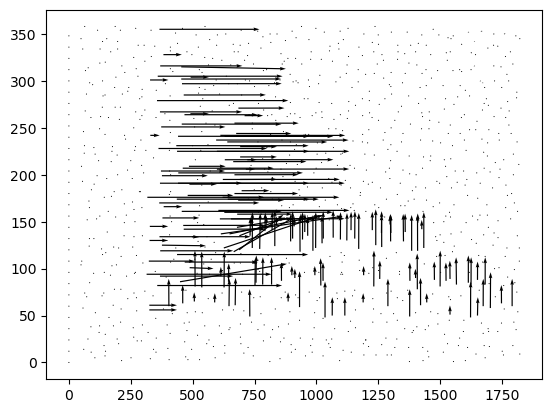

In [85]:
tmp = offset.detach().cpu().numpy()
tmp1 = key.detach().cpu().numpy()
plt.quiver(tmp1[0], tmp1[1], tmp[:,0], tmp[:,1])

In [89]:
#plt.imshow(np.log1p(np.abs(qpol2[0].T)), aspect=5); plt.title('original target'); plt.show()
#plt.imshow(np.log1p(np.abs(qp2_coreg[0].T.detach().cpu().numpy())), aspect=5); plt.title('remapped'); plt.show()
#plt.imshow(np.log1p(np.abs(qpol1[0].T)), aspect=5); plt.title('reference'); plt.show()
ogpf.shape

torch.Size([2, 1920, 384, 8])

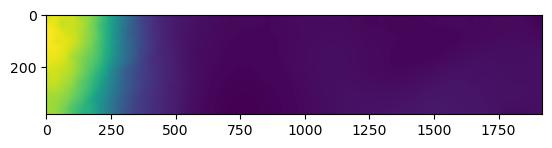

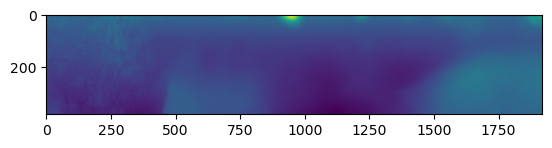

In [149]:
import skimage
#ogpf.shape
#for i in range(ogpf.shape[-1]):
#    samp1 = ogpf[0,:,:,i].detach().cpu().numpy(); samp1[np.isnan(samp1)] = 0;
#    samp2 = ogpf[1,:,:,i].detach().cpu().numpy(); samp2[np.isnan(samp2)] = 0
#    lk_flow += skimage.registration.optical_flow_tvl1(samp1, samp2)
for i in range(qpol1.shape[0]):
    samp1 = np.abs(qpol1[i]); samp1[np.isnan(samp1)] = 0;
    samp2 = np.abs(qpol2[i]); samp2[np.isnan(samp2)] = 0;
    lk_flow += skimage.registration.optical_flow_ilk(samp1, samp2)
lk_flow /= ogpf.shape[-1]
plt.imshow(lk_flow[0].T); plt.show(); plt.imshow(lk_flow[1].T); plt.show();

In [152]:
di,dj = np.meshgrid(np.arange(samp1.shape[0]).astype(float), np.arange(samp2.shape[1]).astype(float), indexing='ij')
tmp = np.array((di + lk_flow[0], dj + lk_flow[1]))
mapped = scipy.ndimage.map_coordinates(samp2, tmp)

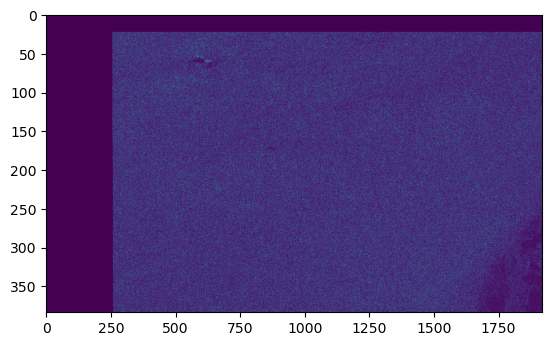

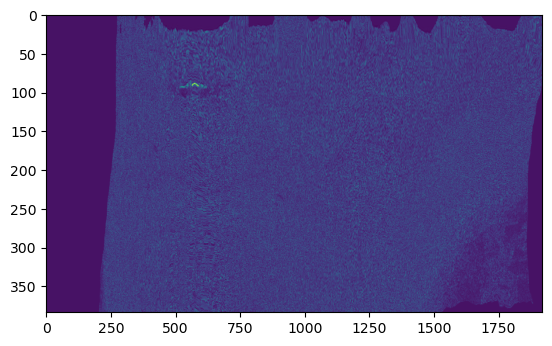

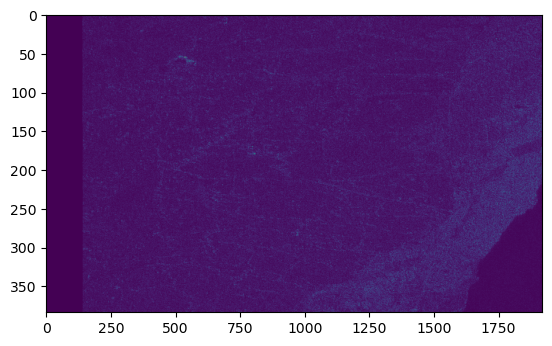

In [153]:
plt.imshow(samp2.T, aspect=3); plt.show(); plt.imshow(mapped.T, aspect=3); plt.show(); plt.imshow(samp1.T, aspect=3); plt.show()